In [47]:
from IPython.display import display, HTML
display(HTML("<style>.container { width:100% !important; }</style>"))

import mdtraj as md
import os, sys
import matplotlib.pyplot as plt
import numpy as np
import matplotlib
from functools import reduce, partial
import scipy
from typing import  Dict, List, Tuple
from importlib import reload
from cycler import cycler
from itertools import chain
# source modules and classes being developed 
from writhe_tools.writhe import (Writhe,
                                 get_segments)


from writhe_tools.plots import (
                                proj2d,
                                fes2d,
                                get_color_list,
                                box_plot,
                                build_matrix_boxplot_grid,
                                lineplot1D)

from writhe_tools.tcca import CCA, tCCA

from matplotlib.lines import Line2D

from writhe_tools.stats import Kmeans, rotate_points, acf, pmf, corr, window_average
from seaborn import kdeplot


from writhe_tools.md_tools import (ResidueDistances,
                                   get_residues,
                                   calc_sa,
                                   traj_slice,
                                   load_traj,
                                   plot_distance_matrix,
                                   residue_distances,                                 
                                   to_contacts,
                                   canonical_residues,
                                    
                                    )


from writhe_tools.utils import (lsdir,
                                group_by,
                                reindex_list,
                                contiguous_bool,
                                to_numpy,
                                num_str,
                                load_dict,
                                save_dict,
                                product, split_list
                                )





import warnings
warnings.filterwarnings("ignore")



fes2d_args = dict(
      cmap="coolwarm",
      bins=55,
      n_contours=8,
      contour_lines=True,
      alpha_lines=0.35,
      alpha_contours=0.6,
      mask=False,
      scatter=True,
      scatter_alpha = .15,
      scatter_size=.05,
      scatter_stride=50,
      scatter_max=.35,
      scatter_min=.15,
      scatter_cmap="coolwarm",
      hide_ax=False,
      extend_border=0.1,
    )



def fill_1d(x, values, indices):
    x[indices] = values
    return x

def fill(x, index, val):
    x[:, index] = val
    return x

def prod(vectors, sum_=False):
    if sum_:
        vectors = [v.sum(axis=-1) for v in vectors]
    return reduce(np.multiply, vectors)

split = partial(np.array_split, indices_or_sections=2, axis=-1) 

ternary_bool = lambda distances : prod([to_contacts(i, 1).any(1) for i in split(distances)])

isin_index = lambda x, y : np.where(np.isin(x, y))[0]




def bootstrap(data: np.ndarray,
              confidence_level: float = 0.68,
              n_resamples: int = 500,
              lower_upper: bool = False,
              method: str = "percentile",
              statistic: callable=np.mean) -> Tuple[float, float]:
    """
    Bootstrap binary data to get the mean and an intentionally wide error estimate.

    Parameters:
        data: binary array of 0s and 1s
        confidence_level: typically 0.99 for wider intervals
        n_resamples: lower values increase variability (default 500)
        method: use 'percentile' to produce wider CIs

    Returns:
        mean: estimated mean of the binary array
        error: half-width of the confidence interval
    """

    res = scipy.stats.bootstrap((data,), statistic=statistic,
                    confidence_level=confidence_level,
                    n_resamples=n_resamples,
                    method=method,
                    random_state=0)

    mean = np.mean(data) if data.ndim == 1 else data.mean(0)
    error = [res.confidence_interval.low, res.confidence_interval.high] if lower_upper\
            else (res.confidence_interval.high - res.confidence_interval.low) / 2
    if data.ndim > 1:error = np.stack(error)
    
    return mean, error


from pyblock.blocking import reblock, find_optimal_block
from collections import Counter
def block_error(x: np.ndarray, lower_upper: bool = False, weights: np.ndarray=None):
    """
    x : (N, d) numpy array with d features and N measurements
    """
    n = x.shape[0]
    blocks = reblock(x.T, weights=weights)
    optimal_indices = np.asarray(find_optimal_block(n, blocks))
    isnan = np.isnan(optimal_indices)
    #mode = Counter(optimal_indices[~isnan].astype(int)).most_common()[0][0]
    optimal_indices[isnan] = -1 # biggest block
    optimal_indices=optimal_indices.astype(int)
    #op
    #print(optimal_indices[0])
    if x.ndim == 1:
        mu = np.sum(x * weights) if weights is not None else x.mean()
        return lu_from_error(x.mean(), blocks[optimal_indices[0]].std_err.item()) if lower_upper else\
                (x.mean(), blocks[optimal_indices[0]].std_err.item())
    else:
        mu = np.sum(x * weights[:, None], 0) if weights is not None else x.mean(0)
        return lu_from_error(mu, np.asarray([blocks[i].std_err[j] for j, i in enumerate(optimal_indices.astype(int))]))\
                if lower_upper else (mu, np.asarray([blocks[i].std_err[j] for j, i in enumerate(optimal_indices.astype(int))]))

def lu_from_error(mean, error):
    if all(isinstance(i, (float, int)) for i in (mean, error)):
        mean, error = [mean], [error]
    return mean, np.array([[mu - err, mu + err] for mu, err in zip(mean, error)]).T

# convenience (hard coded to 2 monomers) function to combine stats and prop error for averages to be taken over both monomers
def monomer_aggr_stats(x, 
                       error:callable=block_error, 
                       lower_upper: bool = False, 
                       fill_bool:np.ndarray=None):
    # compue mean and error over both monomers, aggregate, fill zeros for plotting, give lower, upper errors or absolute error
    ave, err = error(x, lower_upper=False)
    ave = np.add.reduce(split(x.mean(0))) / 2
    err = np.linalg.norm(err.reshape(2, -1), axis=0) / 2
    
    if lower_upper:
        # very simple error propogation here (arguably too simple)
        err = lu_from_error(ave, err)[-1]                   
        if fill_bool is not None:
            ave = fill_1d(np.zeros(len(fill_bool)), ave, fill_bool)
            err = np.stack([fill_1d(np.zeros(len(fill_bool)), i, fill_bool) for i in err])

        return ave, err


    return (ave, err) if fill_bool is None else [fill_1d(np.zeros(len(fill_bool)), i, fill_bool) for i in [ave, err]]


#block_error(np.arange(10000), lower_upper=False)
path = "/data/r1r2"
epi_dir = f"{path}/epi002"
apo_dir = f"{path}/apo"
cam_dir = f"{path}/cam1"
paths = [apo_dir, epi_dir, cam_dir]
labels = ['APO', 'EPI-002', '1aa']

protein_files = ['/data/r1r2/apo/protein.100us.dcd',
                 '/data/r1r2/epi002/protein.100us.dcd',
                 '/data/r1r2/cam1/protein.85us.dcd']


ligand_files = [lsdir(i, keyword=['dcd', 'ligand'], exclude=['wrap'], match=all)[0] for i in paths[1:]]
protein_pdb = '/data/r1r2/epi002/R2_dimer.pdb'
ligand_pdbs = [
               '/data/r1r2/epi002/R2_dimer.epi002.rename.pdb',
               '/data/r1r2/cam1/protein.ligand.pdb',
               ]
helix_pdb = '/data/r1r2/monomer_r1r2_helix.pdb'

trunc = .3
pre_trunc = .3
state_width = .8
state_font_scale = 1.5
codes = np.array(list(md.load(protein_pdb).top.to_fasta()[0]))[:24]


# Computations

In [6]:
# protein only calculations
label = 'APO'
ca_selection = md.load(protein_pdb).top.select('name CA')
sequence, ca_index = get_residues(md.load(protein_pdb))
# 1 letter codes for the monomer sequence (just 1)
codes = np.array(list(md.load(protein_pdb).top.to_fasta()[0]))[:24]

unitcell_lengths = md.load(protein_files[0], top=protein_pdb).unitcell_lengths


ca_distances = ResidueDistances(index_0=np.arange(24),
                                index_1=np.arange(24, 48),
                                traj=md.load(protein_files[0], top=protein_pdb, atom_indices=ca_selection)
                               )

# dimer events from ca_distances
dimer = ca_distances.contacts(1).any(1)
dimer_events = contiguous_bool(bools=dimer)
dimer_lengths = 0.24 * np.fromiter(map(len, dimer_events), float) # scale by physical time

# sort by event length
sort = dimer_lengths.argsort()[::-1]
dimer_events = reindex_list(dimer_events, sort)
dimer_lengths = dimer_lengths[sort]

# structural features
sa = np.stack([calc_sa(md.load(protein_files[0], top=protein_pdb, atom_indices=j), helix_pdb) for j in split(ca_selection)])

dssp = np.where(md.compute_dssp(traj=md.load(protein_files[0], top=protein_pdb)) == 'H', 1, 0)[:, ca_index].reshape(-1, 2, 24
                                                                                                                   ).transpose(1, 0, 2)

writhe = Writhe(xyz=md.load(protein_files[0], top=protein_pdb, atom_indices=ca_selection).xyz)
segments = np.concatenate([get_segments(index0=np.arange(24)),
                           get_segments(index0=np.arange(24, 48)),
                           get_segments(index0=np.arange(24), index1=np.arange(24, 48))
                          ])

writhe_features = writhe.compute_writhe(segments=segments,
                                        cuda=True,
                                        store_results=False,
                                        lengths=unitcell_lengths,
                                        )['writhe_features']
# dimensionality reduction (don't use this if you don't have truly continuous data
tcca = tCCA(writhe_features, lag=10, dim=10,).fit()

# for non-continuous data (replica exchange, metaD, etc, ..) for PCA (or whatever else you want)

# compute the projection and then align to a reference because eigen vects might have flipped sign
proj = tcca.transform(writhe_features); proj = rotate_points(np.load(lsdir(paths[0], keyword='writhe_tcca_lag_')[0])[1:, :2],
                                                             proj, so3=False)

# to cluster with Kmeans
# dtraj, frames_cl = Kmeans(proj, n_clusters=7, n_dim=2)

# Kmeans isn't deterministic, so we use a pre computed clustering to keep consistency with reported values

## WARNING - MUST HAVE REFERNECE AVAILABLE FOR THIS TO WORK - CAN JUST COMMENT THIS OUT AND RECLUSTER USING LINES ABOVE
macrostates = load_dict('density_clusters.pkl')[0]
frames_cl = group_by(macrostates)
centroids = group_by(macrostates, proj, reduction = partial(np.mean, axis = 0))


 # Visualize latent space

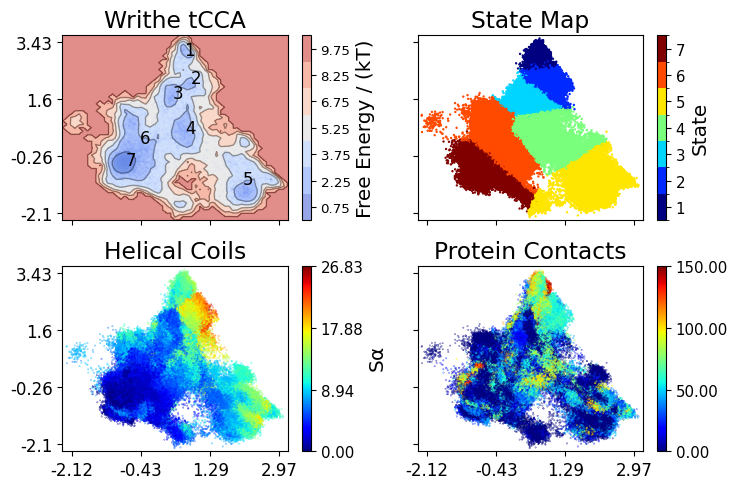

In [7]:
fig, ax = plt.subplots(2, 2, figsize=(7.5, 5), sharey=True, sharex=True)
ax=ax.flat
fes2d(proj,
      cluster_centers=centroids,
      ax=ax[0],
      **fes2d_args,
      title='Writhe tCCA',
      font_scale=1.2)

proj2d(proj, 
       ax=ax[1],
       c=macrostates,
       state_map=True,
       title = 'State Map',
       font_scale=1.2)

proj2d(proj,  ax=ax[2], c=sa.sum((0,2)),
       cmap='jet', title = 'Helical Coils',
       font_scale=1.2,dot_size=.05,
       vmin=0, cbar_label=r'S$\alpha$')

proj2d(proj, 
       ax=ax[3],
       c=ca_distances.contacts(1).sum(-1),
       cmap='jet',
       title = 'Protein Contacts',
       font_scale=1.2,
       vmin=0,vmax=150,
       dot_size=.05)

fig.tight_layout()
fig.savefig(f'{paths[0]}/projections.png',
            dpi=1000, bbox_inches='tight')

 # protein contacts (CA-CA distance < 1 nm) and helical propensities (DSSP algorithm)

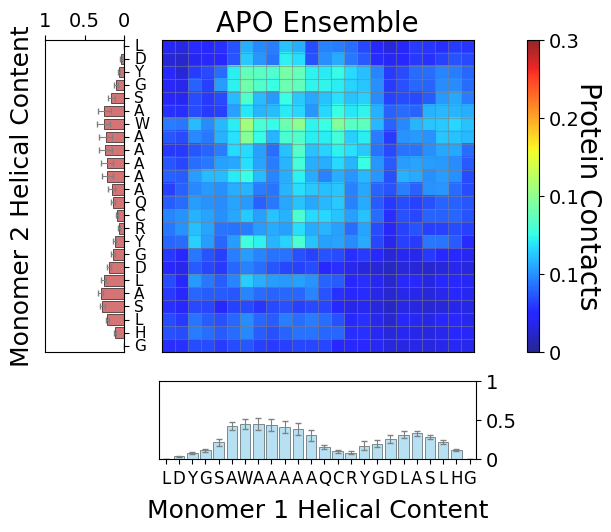

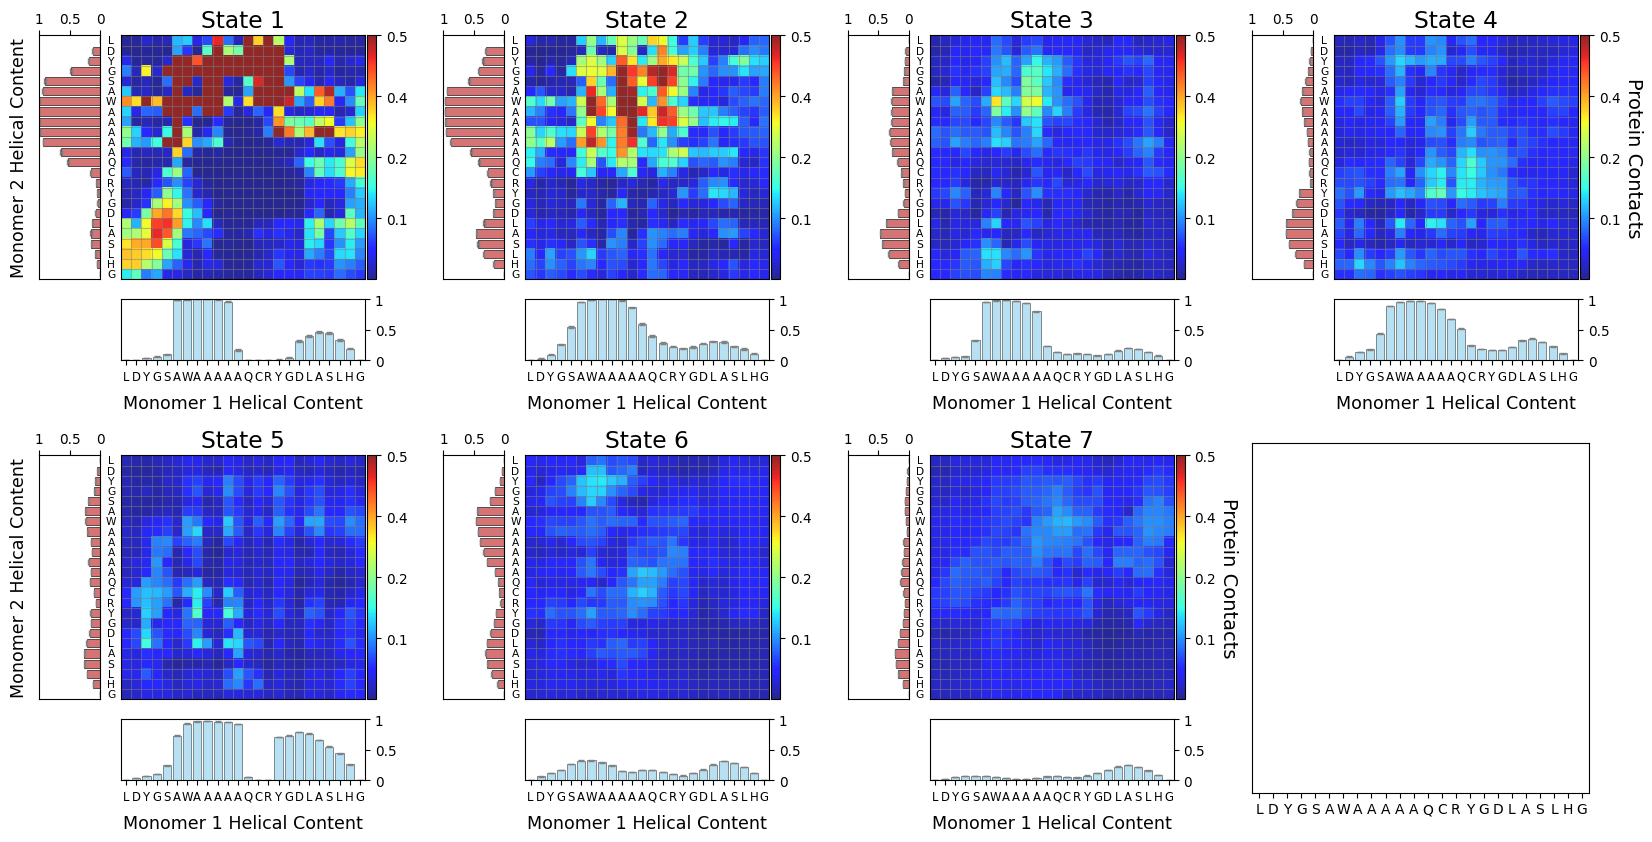

In [56]:
import writhe_tools
reload(writhe_tools)
reload(writhe_tools.plots)
from writhe_tools.plots import build_matrix_boxplot_grid
dssp_error = split(block_error(dssp.transpose(1, 0, 2).reshape(-1, 48))[1])

build_matrix_boxplot_grid(ca_distances.matrix(contacts=True, cut_off=1).mean(0).T,
                          dssp[0].mean(0),
                          dssp[1].mean(0),
                          bottom_errors=dssp_error[0],
                          left_errors=dssp_error[1],
                          cmap='jet',
                          title=f'{label} Ensemble',
                          bottom_title='Monomer 1 Helical Content',
                          vmin=0,
                          vmax=.3,
                          marginal_max=1,
                          left_title='Monomer 2 Helical Content',
                          cbar_label='Protein Contacts',
                          ticks=codes,
                          ecolor='gray',
                          path=f'{paths[0]}/protein_protein_helix_ensemble.png'
                         )

fig, axes = plt.subplots(2, 4, figsize=(20, 10), sharey=True, sharex=True)
for i, (ax, frames) in enumerate(zip(axes.flat, group_by(macrostates))):
    dssp_error = split(bootstrap(dssp.transpose(1, 0, 2).reshape(-1, 48)[frames], 0.999)[1])

    build_matrix_boxplot_grid(ca_distances.matrix(contacts=True, cut_off=1, index=frames).mean(0).T,
                          dssp[0][frames].mean(0),
                          dssp[1][frames].mean(0),
                          title_size=24,
                          bottom_errors=dssp_error[0],
                          left_errors=dssp_error[1],
                          cmap='jet',
                          title=f'State {i+1}', #f'{label} : State {i+1}',
                          bottom_title='Monomer 1 Helical Content',
                          vmin=0,
                          vmax=.5,
                          marginal_max=1,
                          left_title='Monomer 2 Helical Content' if (i == 0 or i == 4) else '',
                          cbar_label='Protein Contacts' if (i == 3 or i == 6) else '' ,
                          ticks=codes,
                          ax=ax,
                          font_scale=.7,
                          #path=f'{paths[0]}/protein_protein_helix_state_{i+1}.png',
                             )
#fig.tight_layout()


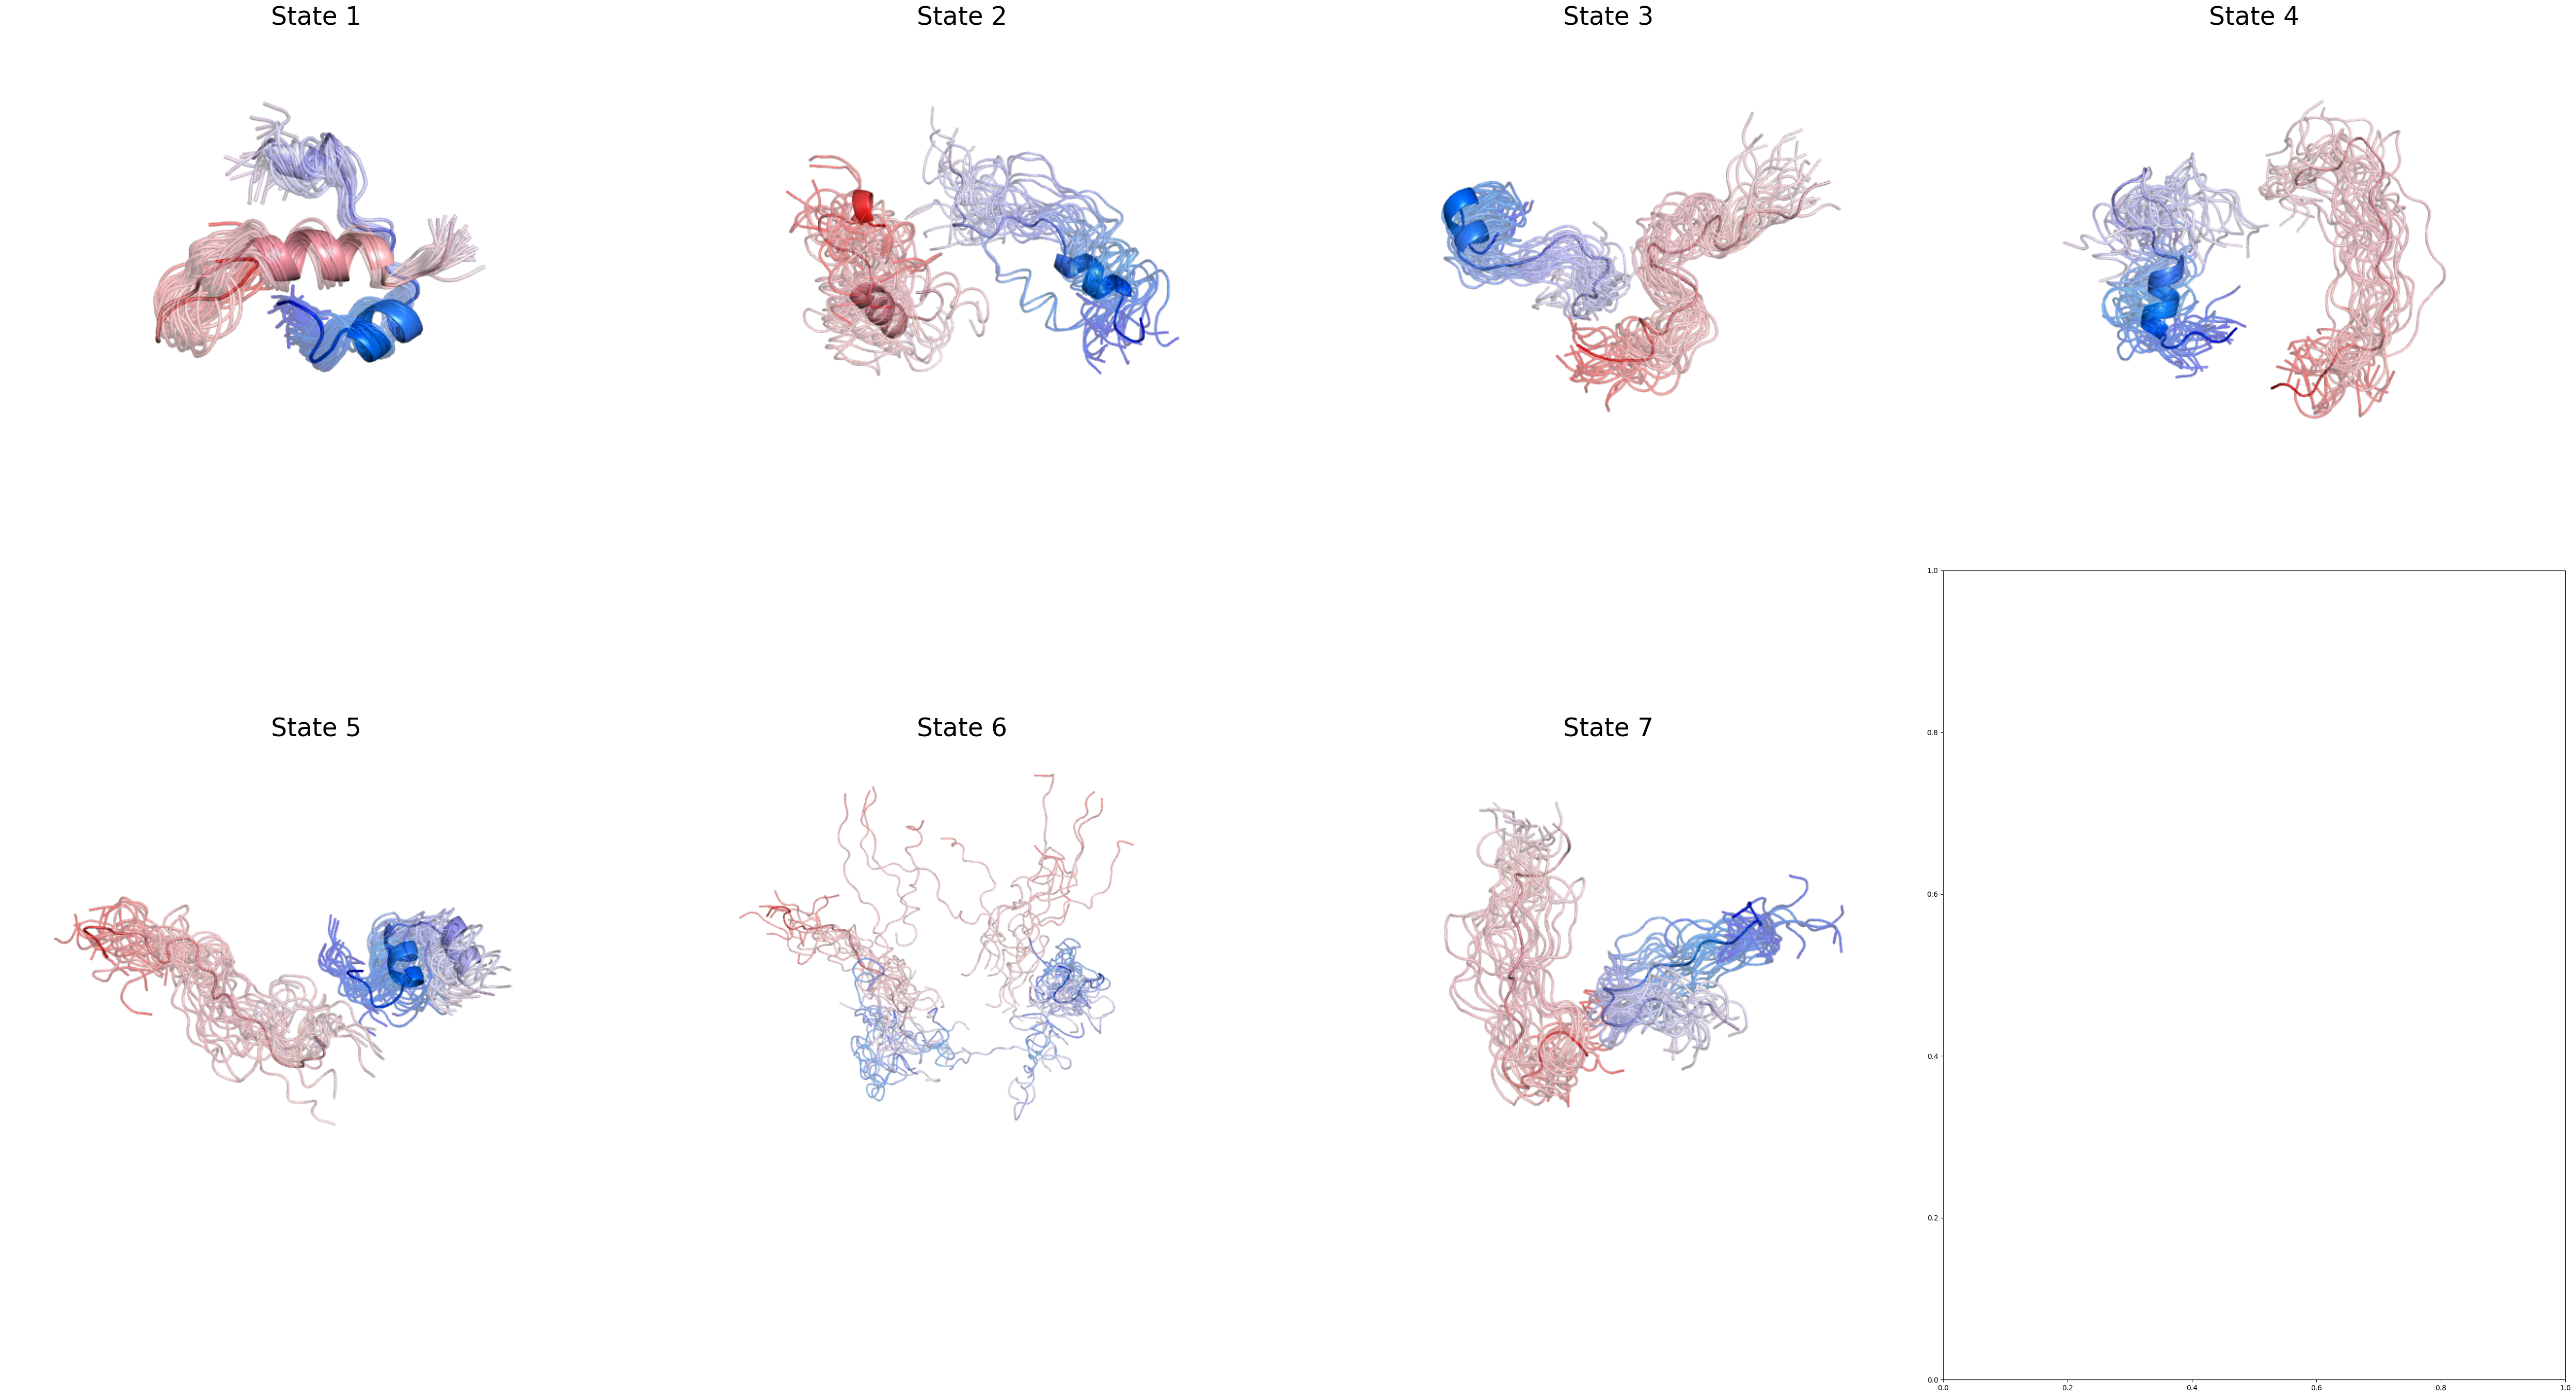

In [139]:
from visualize import visualize_clustering
from writhe_tools.md_tools import rmsd_sort
#features = np.concatenate([dssp.transpose(1, 0, 2).reshape(-1, 48), ca_distances.contacts(1)], 1)

features =  writhe_features #np.concatenate([writhe_features, 5 * sa.transpose(1, 0, 2).reshape(-1, 38)], 1) # writhe_features # proj[:, :2]
mus = group_by(macrostates, features, partial(np.mean, axis=0))
writhe_centroids = []
for frames, center in zip(group_by(macrostates), mus):
    writhe_centroids.append(frames[np.linalg.norm(features[frames] - center, axis=-1).argsort()])

traj = md.load('./apo_pbc_correct.dcd', top=protein_pdb).center_coordinates()
fig, axes = plt.subplots(2, 4, figsize=(50, 30))
for i, (frames, ax) in enumerate(zip(writhe_centroids, axes.flat)):
    indices = rmsd_sort(frames, traj, 0)
    visualize_clustering(traj,
                         indices,
                         path='./',
                         name = f"State {i+1}",
                         n_frames=25, 
                         draw_style='cartoon',
                         ensemble_draw_style='loop',
                         transparency=.45,
                         ax=ax)
    ax.set_title(f"State {i+1}", size=35)
fig.tight_layout()

In [126]:
writhe.compute_writhe(1,
                      cuda=True,
                      store_results=True,
                      lengths=unitcell_lengths)


{'length': 1,
 'n_points': 48,
 'n': 416660,
 'writhe_features': array([[ 0.07282721,  0.0850312 , -0.02672937, ...,  0.08292271,
          0.0079792 ,  0.07954123],
        [ 0.04256969,  0.09085549, -0.01979836, ...,  0.10065888,
          0.07301756,  0.08325159],
        [ 0.06122436,  0.03570015, -0.02332329, ...,  0.07903407,
          0.07984476, -0.00822239],
        ...,
        [ 0.00742197, -0.00691142,  0.00730982, ..., -0.03185304,
          0.01204761, -0.02455041],
        [ 0.03817464,  0.00101899,  0.00633033, ..., -0.02765206,
          0.01646464, -0.01539113],
        [ 0.05733339,  0.00402457,  0.02180568, ..., -0.02566213,
          0.00271614, -0.02611078]], dtype=float32),
 'segments': array([[ 0,  1,  2,  3],
        [ 0,  1,  3,  4],
        [ 0,  1,  4,  5],
        ...,
        [43, 44, 45, 46],
        [43, 44, 46, 47],
        [44, 45, 46, 47]])}

In [127]:
writhe.writhe_features[:, (writhe.segments[:, :2] == np.array([23, 24])).all(1) | (writhe.segments[:, 2:] == np.array([23, 24])).all(1)
                          ] = 0

In [156]:
ticks = np.tile(np.array([f'{j}{i + 1}' for i, j in enumerate(codes[1:])] + ['']), 2)[:-1]

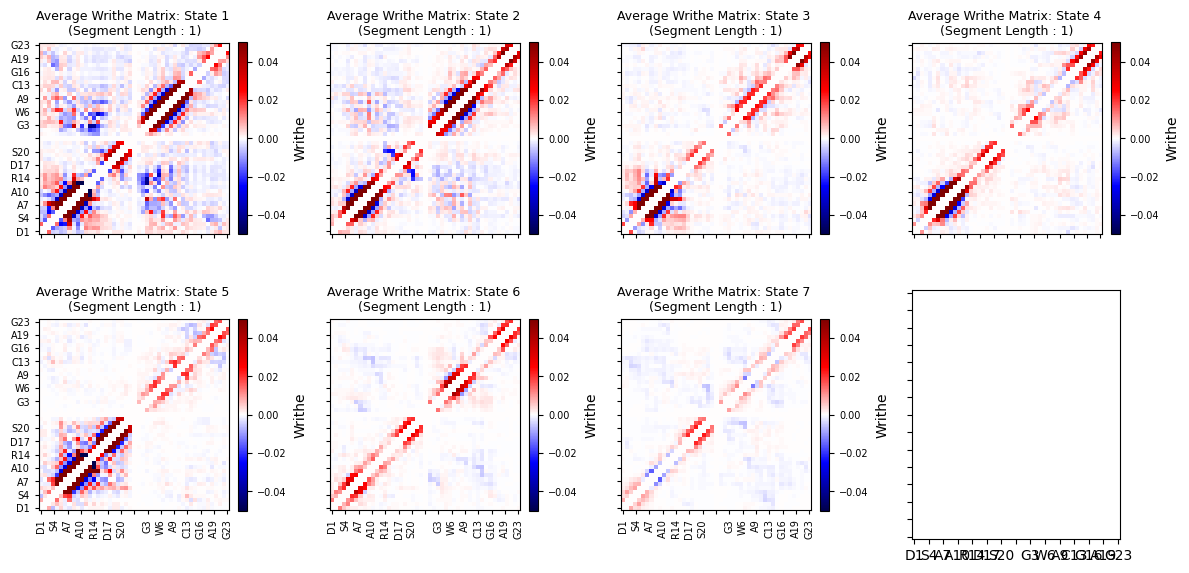

In [166]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6), sharex=True, sharey=True)
for i, (ax, frames) in enumerate(zip(axes.flat, group_by(macrostates))):
    writhe.plot_writhe_matrix(frames,
                              ax=ax, 
                              dscr=f'State {i+1}',
                              vmax=0.05,
                              laplacian=False,
                              yticks=np.tile(np.array([f'{j}{i + 1}' for i, j in enumerate(codes[1:])] + ['']), 2),
                              xticks=np.tile(np.array([f'{j}{i + 1}' for i, j in enumerate(codes[1:])] + ['']), 2),
                              label_stride=3, xticks_rotation=90
                             )
fig.tight_layout()
    

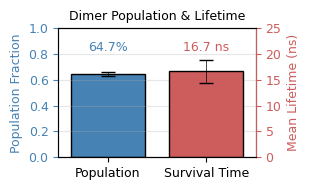

In [35]:
from matplotlib.collections import LineCollection

# --- helper: shift all x-positions for artists on an Axes (boxes, whiskers, errorbars)
def _shift_x(ax, dx):
    # patches (boxes)
    for p in ax.patches:
        p.set_x(p.get_x() + dx)

    # standard lines (medians, caps, etc.)
    for ln in ax.lines:
        xd = ln.get_xdata()
        if xd is not None and len(np.atleast_1d(xd)):
            ln.set_xdata(np.asarray(xd) + dx)

    # collections (whiskers/errorbars often stored as LineCollection)
    for coll in ax.collections:
        if isinstance(coll, LineCollection):
            segs = coll.get_segments()
            if segs:
                coll.set_segments([seg + np.array([dx, 0]) for seg in segs])
        elif hasattr(coll, "get_offsets"):
            offs = coll.get_offsets()
            if offs is not None and len(offs):
                coll.set_offsets(offs + np.array([dx, 0]))

fig, ax1 = plt.subplots(figsize=(3.2, 2))

# --- Left axis: dimer population fraction (steelblue) ---
mu_pop, err_pop = block_error(dimer)
box_plot(
    [mu_pop],
    errors=[err_pop],
    labels=['Population'],
    error_capsize=5,
    error_linewidth=.5,
    error_capthick=1,
    error_color='black',
    color_list=['steelblue'],
    alpha=1,
    font_scale=state_font_scale,
    title='Dimer Population & Lifetime',
    rotation=0,
    trunc=trunc,
    pre_trunc=pre_trunc,
    ymin=0,
    ymax=1,
    width=0.45,
    ax=ax1
)
ax1.set_ylabel('Population Fraction', color='steelblue')
ax1.tick_params(axis='y', colors='steelblue')
ax1.spines['left'].set_color('steelblue')

# --- Right axis: mean dimer lifetime (indianred) ---
ax2 = ax1.twinx()
mu_life = np.mean(dimer_lengths)
err_life = bootstrap(dimer_lengths)[-1]
box_plot(
    [mu_life],
    errors=[err_life],
    labels=['Survival Time'],
    error_capsize=5,
    error_linewidth=.5,
    error_capthick=1,
    error_color='black',
    color_list=['indianred'],
    alpha=1,
    font_scale=state_font_scale,
    rotation=0,
    trunc=trunc,
    pre_trunc=pre_trunc,
    ymin=0,
    ymax=25,
    width=0.45,
    ax=ax2
)
ax2.set_ylabel('Mean Lifetime (ns)', color='indianred')
ax2.tick_params(axis='y', colors='indianred')
ax2.spines['right'].set_color('indianred')

# --- Separate the boxes on x: slide left-axis box left, right-axis box right ---
left_x, right_x = -0.3, +0.3
_shift_x(ax1, left_x)
_shift_x(ax2, right_x)

# --- X ticks/labels aligned with box centers; hide twin x-ticks
ax1.set_xlim(-0.6, 0.6)
ax1.set_xticks([left_x, right_x])
ax1.set_xticklabels(['Population', 'Survival Time'])
ax2.tick_params(axis='x', which='both', bottom=False, top=False, labelbottom=False)

# --- Grid + annotations (colors match axes)
ax1.grid(True, alpha=0.3, axis='y')
yl1 = ax1.get_ylim(); yl2 = ax2.get_ylim()
ax1.text(left_x, yl1[0] + 0.8*(yl1[1]-yl1[0]), f'{100*mu_pop:.1f}%',
         color='steelblue', ha='center', va='bottom', fontsize=9)
ax2.text(right_x, yl2[0] + 0.80*(yl2[1]-yl2[0]), f'{mu_life:.1f} ns',
         color='indianred', ha='center', va='bottom', fontsize=9)

fig.tight_layout()
plt.show()


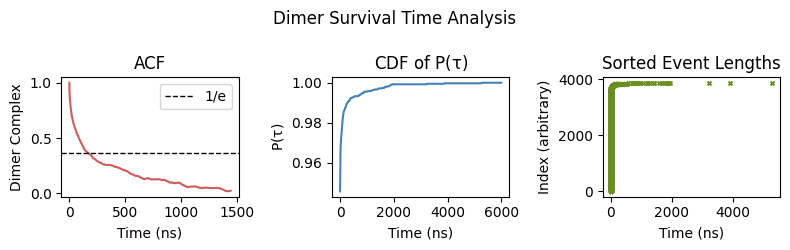

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(8, 2.5))

ac = acf(dimer)
#get the correlation time
#tau.append(get_tau(ac))
axes[0].plot(np.arange(0, 6000) * 0.24,  # scale the time
             ac[:6000],
             c="indianred",
            )
bins=300
axes[1].plot( np.linspace(0, 6000, bins), np.cumsum(pmf(dimer_lengths, bins=bins, range=(0, 6000))[0]), c='steelblue')
axes[2].scatter(dimer_lengths[::-1], np.arange(len(dimer_lengths)), c='olivedrab', s=8, marker='x')



axes[2].set_xlabel('Time (ns)')
axes[2].set_ylabel('Index (arbitrary)')
axes[2].set_title('Sorted Event Lengths')

axes[1].set_ylabel(r'P($\tau$)')
axes[1].set_xlabel('Time (ns)')
#axes[1].legend()
axes[1].set_title('CDF of ' + r'P($\tau$)')

axes[0].axhline(y=1/np.exp(1),
                linestyle='--',
                color='black',
                linewidth=1,
                label='1/e',
               )

axes[0].set_xlabel(r"Time (ns)")
axes[0].set_ylabel("Dimer Complex")
axes[0].legend(ncol=2)
axes[0].set_title('ACF')

#axes[2].legend()
fig.suptitle('Dimer Survival Time Analysis')
fig.tight_layout()

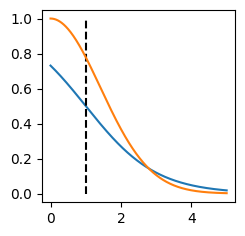

In [27]:
def sigmoid(x, shift=1, scale=1):
    return 1 - 1 / (1 + np.exp(-scale * (x - shift)))
x = np.linspace(0, 5, 1000)
plt.figure(figsize=(2.5, 2.5))
plt.plot(x, sigmoid(x))
plt.vlines(1, 0,1, color='black', ls='--')
plt.plot(x, np.exp(-.25 * x**2))

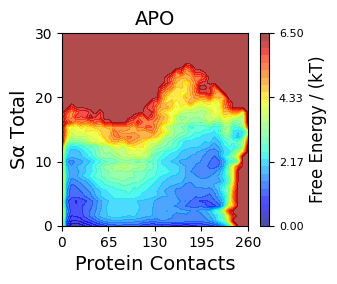

In [32]:
from writhe_tools.writhe_numba import pbc_correct
from writhe_tools.stats import cross_correlation, plot_cross_correlation
extent = ((0, 260), (0, 30))
fes2d(
      sigmoid(ca_distances.distances).sum(-1),
    #np.exp(-.25 * ca_distances.distances**2).sum(-1),
      sa.sum((0,-1)),
      ylabel=r'S$\alpha$'+" Total",
      xlabel="Protein Contacts",
      bins=40,
      tick_decimals=0,
      title=label,
      mask=False,
      contour_lines=False,
      alpha_contours=.7,
      alpha_lines=.1,
      mask_thresh=5,
      n_contours=30,
      nxticks=5, 
      extent=extent,figsize=(3, 2.5)
)
plt.savefig(f'./{label}_helix_contact_fes', dpi = 1000, bbox_inches = 'tight')

Text(0.5, 1.0, 'S$\\alpha$(t) * Protein Contacts(t + $\\tau$)')

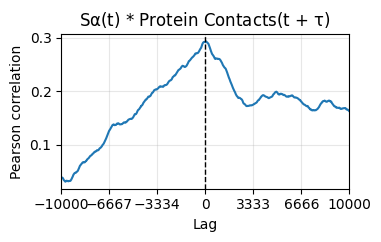

In [33]:
from writhe_tools.writhe_numba import pbc_correct
from writhe_tools.stats import cross_correlation, plot_cross_correlation
#dist = np.power(pbc_correct(writhe.xyz[:, :24].mean(1) - writhe.xyz[:, 24:].mean(1), unitcell_lengths), 2).sum(-1)**(1/2)
lags, corr = cross_correlation(sa.sum((0,-1)),
                                       #ca_distances.contacts(1).mean(-1),
                                       np.exp(-.25 * ca_distances.distances**2).sum(-1),
                                     )
ax=plt.subplots(1, 1,figsize=(4, 2.5))[-1]
plot_cross_correlation(lags, corr, 10000, normalize=False, ax=ax)
ax.set_title(r'S$\alpha$(t) * Protein Contacts(t + $\tau$)')

Text(0.5, 1.0, 'Event Protein Contact distributions')

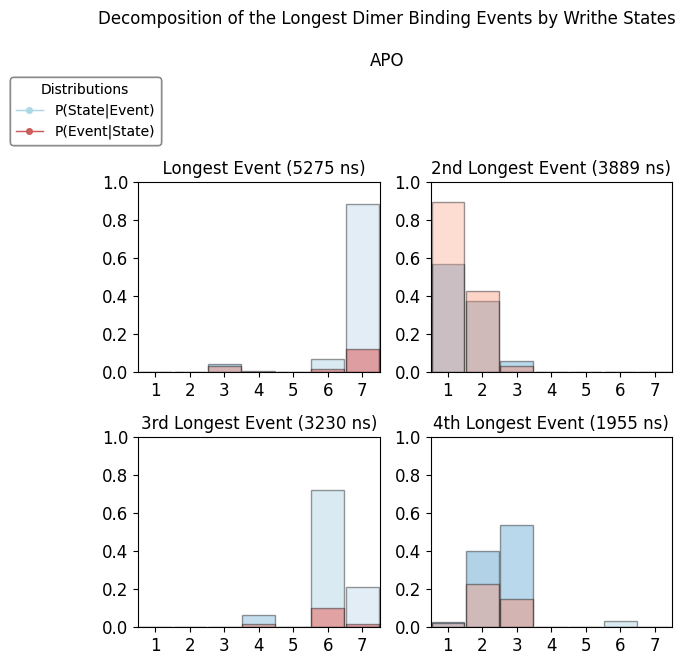

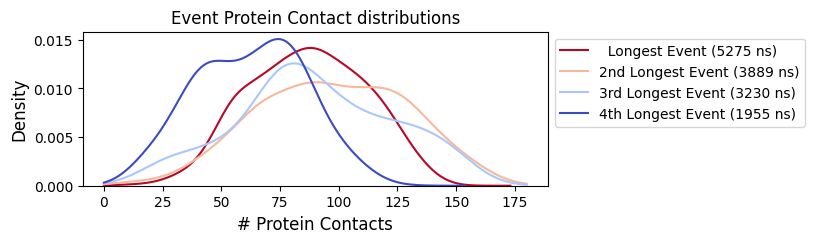

In [42]:
import seaborn as sns
fig, axes = plt.subplots(2,2, figsize=(6, 6))
event_title = dict(zip([0, 1, 2, 3], ' ,2nd,3rd,4th'.split(',')))
for i, (frames, length, ax) in enumerate(zip(dimer_events, dimer_lengths, axes.flat)):

    cSE = pmf(macrostates[frames], np.unique(macrostates).size, norm=False, range=(0, np.unique(macrostates).size,))[0]
    cS =  pmf(macrostates, np.unique(macrostates).size, norm=False, range=(0, np.unique(macrostates).size,))[0]
    pES = cSE / cS
    pSE = cSE / cSE.sum()
    
    box_plot(pSE, label_stride=1, cmap='Blues_r',
             ax=ax, alpha=.4, labels=np.arange(len(pES))+1,
             font_scale=2, trunc=trunc, pre_trunc=pre_trunc)
    
    box_plot(pES, label_stride=1, cmap='Reds',
             ax=ax, alpha=.4, font_scale=2,#ylabel="Contact\n Populaton", 
             labels=np.arange(len(pES))+1,
             rotation=0, trunc=trunc, pre_trunc=pre_trunc, ymin=0, ymax=1,
            title = f'{event_title[i]} Longest Event ({length:.0f} ns)')
    
    legend_elements = [Line2D([0], [0],
                              marker="o", 
                              color=color,
                              label=l,
                              markerfacecolor=color,
                              markersize=4,
                              lw=1)
                       for i, (l, color) in enumerate(zip(["P(State|Event)", "P(Event|State)"],
                                                 ["lightblue", "indianred"]))]
    
    fig.legend(handles=legend_elements,title="Distributions",loc="upper left",
           fontsize=10, title_fontsize=10, edgecolor=(.5,.5,.5), ncol=1,
           bbox_to_anchor = [-.14,1])
    
    fig.suptitle(f"Decomposition of the Longest Dimer Binding Events by Writhe States\n\n{label}", y=1.1)

fig.tight_layout()


fig, ax = plt.subplots(1, 1, figsize=(6,2))
for i, (frames, length, color) in enumerate(zip(dimer_events[:4], dimer_lengths, get_color_list(4,'coolwarm_r'))):
    
    sns.kdeplot(ca_distances.contacts(1)[frames].sum(-1),
                label=f'{event_title[i]} Longest Event ({length:.0f} ns)',
                common_grid=True,
                ax=ax,
                clip=(0,180),
                bw_adjust=2,
                color=color)

ax.legend(ncol=1, bbox_to_anchor=[1,1])
ax.set_xlabel('# Protein Contacts', size=12)
ax.set_ylabel('Density', size=12)
ax.set_title('Event Protein Contact distributions', 
                #size=15,
               )

In [44]:
import pandas
from pandas import DataFrame
from IPython.display import display, Markdown
cols = ['Population %', r'Protein Contacts',  r'$S\alpha$', 'Dimer %', 'Ligand Contacts', 'Ternary %']

rows = []

rows.append(group_by(macrostates, reduction=lambda x : 100 * x.sum() / len(macrostates)))

rows.append(group_by(macrostates,
                    ca_distances.contacts(1).sum(-1),
                    np.mean))


rows.append(group_by(macrostates, sa.sum((0, 2)), np.mean))

rows.append(100 * group_by(dtraj,
                           dimer,
                           np.mean))


display(Markdown(f'{label} State Averaged Observables'))
display(pandas.DataFrame(np.array(rows).T.round(1), columns=cols[:4], index=np.arange(1, len(rows[0]) + 1)))
        
    

APO State Averaged Observables

,Population %,Protein Contacts,$S\alpha$,Dimer %
1,2.5,98.3,13.0,99.0
2,3.4,73.2,15.3,98.7
3,7.1,37.4,7.8,72.6
4,12.6,41.0,9.1,72.5
5,12.6,30.9,10.2,61.4
6,22.7,33.1,5.1,56.1
7,39.2,34.7,2.0,61.8


Text(0.5, 0, 'Rg (nm)')

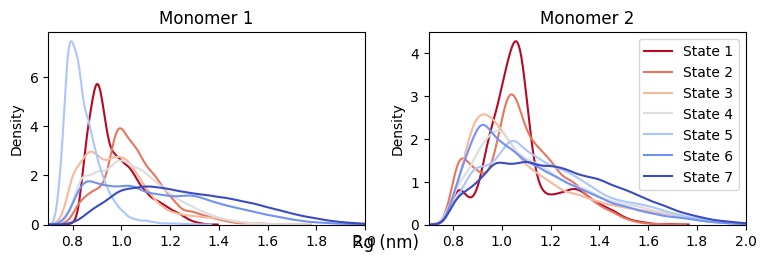

In [93]:
selection = ' or '.join([f'residue {j}' for j, i in enumerate(sequence) if num_str(i, reverse=True) in canonical_residues])
rgs = [md.compute_rg(traj_slice(md.load(protein_files[0], top=protein_pdb), ' or '.join(s))) for s in split_list(selection.split(' or '), 2)]

colors = get_color_list(7, 'coolwarm_r')

fig, axes = plt.subplots(1, 2, figsize=(9, 2.5), sharex=True, sharey=False)
for i, (frames, c) in enumerate(zip(group_by(macrostates), colors)):
    kdeplot(rgs[0][frames], ax=axes[0], color=c, label=f'State {i+1}')
    kdeplot(rgs[1][frames], ax=axes[1], color=c, label=f'State {i+1}')
axes[1].legend()
axes[0].set_title('Monomer 1')
axes[1].set_title('Monomer 2')
axes[0].set_xlim(0.5, 2)
axes[1].set_xlim(0.7, 2)
fig.supxlabel('Rg (nm)', y=0)

 # Markov Modeling

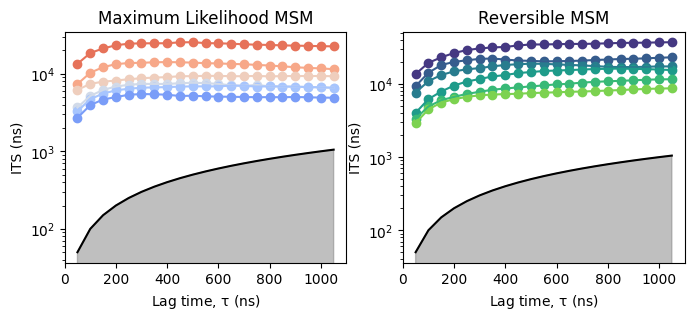

In [75]:
import deeptime
from deeptime.markov.msm import MaximumLikelihoodMSM
from deeptime.util.validation import ck_test
from deeptime.markov.msm import BayesianMSM
from deeptime.plots import plot_implied_timescales
from deeptime.util.validation import implied_timescales


from writhe_tools.msm_tools import MarkovModel


mode =lambda x : np.bincount(x).argmax()

counter = lambda x, lag : deeptime.markov.TransitionCountEstimator(lagtime=int(lag),
                                                              count_mode="effective"
                                                             ).fit(x).fetch_model()
def bayes_mfpt_matrix(bmsm, sets, ci=0.68):
    mfpt = np.zeros((len(sets), len(sets)))
    mfpt_err = np.zeros((len(sets), len(sets)))
    for i in range(len(sets)):
        for j in range(len(sets)):
            stats = bmsm.gather_stats("mfpt",
                                      A=sets[i],
                                      B=sets[j],
                                      confidence = ci
                                      )
            mfpt[i, j] = stats.mean
            mfpt_err[i, j] = (abs(stats.mean - stats.L) + abs(stats.mean - stats.R)) / 2
    
    return mfpt.T, mfpt_err.T

def bayes_mfpt(bmsm, i, j, ci: float=0.68):
    stats = bmsm.gather_stats("mfpt",
                              A=i,
                              B=j,
                              confidence=ci)
    err =  (abs(stats.mean - stats.L) + abs(stats.mean - stats.R)) / 2
    return stats.mean, err

def flux_matrix(sample, metastable_sets):
    nsets = len(metastable_sets)
    matrix = np.zeros((nsets, nsets))
    for i in range(nsets):
        for j in range(nsets):
            if i != j:
                matrix[i, j] = sample.reactive_flux(metastable_sets[i].astype(int), metastable_sets[j].astype(int)).total_flux
    return matrix





# to rerun

# increase tCCA lag time for longer lag time MSM (doesn't visibly change the FES)

# tcca = tCCA(writhe_features, lag=250, dim=50, epsilon=1e-6).fit()
# proj = tcca.transform()
# dtraj = Kmeans(proj, 250, 5, max_iter=500)[0]
# np.save('best_micro_dtraj_apo.npy', msm.dtraj)

dtraj = np.load('best_micro_dtraj_apo.npy')
lag, steps = 50, 20
lags = np.arange(1, steps + 1) * lag

# regular msm estimation
msm = MarkovModel(dtraj, 1).estimate_msm(lag, steps, reversible=False)
sets = group_by(*group_by(msm.dtraj, macrostates, mode, return_keys=True))
msm_rev =  MarkovModel(msm.dtraj).estimate_msm(lag, steps, reversible=True)

fig, ax = plt.subplots(1, 2, figsize=(8, 3))
msm.its('msm', n_its=6, ax=ax[0], cmap='coolwarm_r')
msm_rev.its('msm', n_its=6, ax=ax[1])
ax[0].set_title('Maximum Likelihood MSM')
ax[1].set_title('Reversible MSM')

#ax[0].set_ylim(1000, 50000)

# bayes = [BayesianMSM(n_samples=500, reversible=False).fit(counter(msm.dtraj, l)).fetch_model() for l in lags]
# save_dict('apo_bayes.pkl', bayes)

bayes = load_dict('apo_bayes.pkl')

# ensure lags and steps match the loaded bayes models
# lag = bayes[0].lagtime
# steps = len(bayes)
# lags = [i.lagtime for i in bayes]

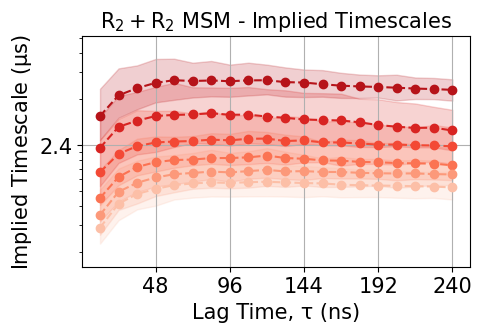

In [72]:

from writhe_tools.utils import symbols
import matplotlib.ticker as ticker

its = implied_timescales(bayes)
fig, ax = plt.subplots(1, 1, figsize=(5, 3))
ax.set_yscale("log")
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{x * 0.24e-3:.1f}"))
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{x * 0.24:.0f}"))
plot_implied_timescales(its,
                        ax=ax,
                        colors = get_color_list(6, 'Reds_r', 60, 45),
                        n_its=6,
                        show_mle=False)
#ax.set_xticks(np.arange(len(lags)), np.round(lags * .24, 1))
#ax.set_xlim(5, 15)
ax.set_ylabel(r"Implied Timescale ($\mu$s)", size=15)
ax.set_xlabel(f"Lag Time, {symbols('tau')} (ns)", size=15)
plt.title(r"$R_{2} + R_{2}$ MSM - Implied Timescales",size = 15)
ax.tick_params('both', labelsize = 15)
ax.tick_params('x', labelsize = 15)
#ax.set_xlim(0, 420)
ax.set_ylim(1600,)
ax.grid()

In [73]:
msm_index = -10

<Axes: title={'center': 'MFPT Matrix : APO'}, xlabel='$State_{i}$', ylabel='$State_{j}$'>

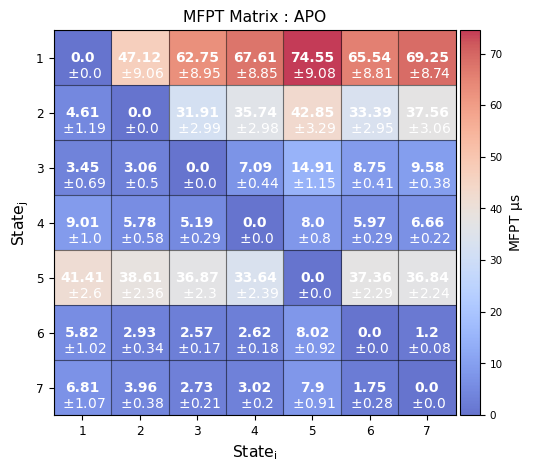

In [76]:
from writhe_tools.plots import annotated_matrix_plot

mfpt_mean, mfpt_error = bayes_mfpt_matrix(bayes[msm_index], sets)

annotated_matrix_plot(mfpt_mean * 0.24e-3,
                      mfpt_error * 0.24e-3,
                      decimals=2,
                      cmap='coolwarm', 
                      alpha=.78,
                      title = f'MFPT Matrix : {label}',
                      font_scale=.25,
                      cbar_label=r'MFPT $\mu$s',
                      grid=True, 
                      grid_alpha=.3, 
                      figsize=(5.5,5)
                      )

<Axes: title={'center': 'R2 + R2 APO MSM Macrostate Flux Matrix'}, xlabel='$State_{i}$', ylabel='$State_{j}$'>

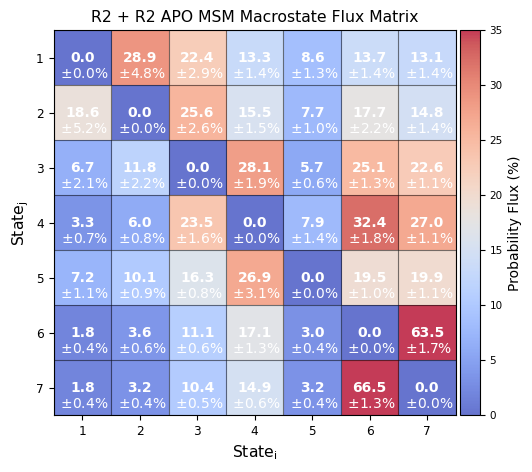

In [77]:
flux = np.stack([flux_matrix(i, sets) for i in bayes[msm_index].samples])
flux /= flux.sum(2, keepdims=True)
flux_mu = flux.mean(0)
flux_err = np.diff(np.percentile(flux, [2.5, 97.5], axis=0), axis=0).squeeze() / 2 


annotated_matrix_plot(flux_mu * 100,
                      flux_err * 100,
                      decimals=1,
                      cmap='coolwarm', 
                      alpha=.78,
                      font_scale=.25,
                      title = r"R2 + R2 APO MSM Macrostate Flux Matrix",
                      unit = "%",
                      cbar_label = r"Probability Flux (%)",
                      grid=True, 
                      grid_alpha=.3, 
                      figsize=(5.5,5), vmax=35,
                      )

In [ ]:
def get_amplitudes(lvecs, obs, remove_mean=True):
    obs = obs.squeeze()
    
    obs = obs.reshape(len(lvecs), -1)

    return ((obs - obs.mean(0) if remove_mean else obs).T @ lvecs.T)**2

    
def msm_relaxation(obs, eigvals, lvecs, steps=10, lag=1, dt=1, first_term:bool=False):
    """
    lvecs :: (vectors of length n_states in the rows) :: (np.diag(msm.stationary_distribution) @ msm.eigenvectors_right()).T
    eigvals :: (n_vecs, )
    obs :: (n_states, n_features)
    
    """
    n_states = len(obs)
    
    ci = get_amplitudes(lvecs, obs)
    
    tex = get_timescales(eigvals, steps, lag, dt)
    
    return ci[None, :, 0] * int(first_term) + (ci[None, :, 1:] * tex.reshape(steps, 1, n_states-1)).sum(-1) 


def get_timescales(eigvals, steps, lag, dt):
    return np.stack([- lag * dt / np.log(abs(eigvals[1:])**i) for i in range(1, steps + 1)])

def get_lagged_eigvals(eigvals, steps=10, lag=1, dt=1):
    return np.stack([eigvals[1:]**(i * dt * lag) for i in range(1, steps + 1)])

def acf_from_spectral(obs, eigvals,  lvecs, steps=10, lag=1, dt=1, first_term=False):
    
    n_states = len(lvecs)
    
    ci = get_amplitudes(lvecs, obs) # shape : (d, n_states)
    
    lam_t = get_lagged_eigvals(eigvals, steps, lag, dt)
    
    return ci[None, :, 0] * int(first_term) + (ci[None, :, 1:] * lam_t.reshape(steps, 1, n_states-1)).sum(-1)
    

def acf_from_tmat(obs, tmat, lvecs, steps=10, lag=1, dt=1):
    
    pi = lvecs[0]
    
    obs = obs.squeeze()
    obs = obs.reshape(len(tmat), -1)
    obs = obs - obs.mean(0)
    
    return np.stack([(obs * (pi.reshape(-1, 1) * np.linalg.matrix_power(tmat, i * lag *dt) @ obs)).sum(0) for i in range(1, steps + 1)])

def calc_cpmg(obs, eigvals, lvecs, tau, nu, lag, dt, steps=10, first_term=False):
    
    ci = get_amplitudes(lvecs, obs)
    
    scale = (2 * np.pi * nu) ** 2
    
    n_states = len(eigvals)
    
    tex = get_lagged_eigvals(eigvals, steps, lag, dt).reshape(steps, 1, n_states - 1)
    
    # ci[None, :, 0] * int(first_term) 
    
    return (scale * ((ci[None, :, 1:] * tex) * (1 - (tex / tau) * np.tanh(tau / tex))).sum(-1)).squeeze()